# 9 — Résultats sur l'échantillon Out-of-Time · Segment : Comptes joints

Dernière étape du dossier : le système de notation retenu (variante **v2** : 9 variables, grille PDO, 4 CHR, PD LRA
+ MoC) est appliqué à l'**échantillon Out-of-Time** (OOT), base fournie séparément et postérieure à la période de
développement (cours 1.5). C'est le contrôle le plus exigeant : la population, la conjoncture et le taux de défaut
peuvent avoir changé.

**Rien n'est réestimé.** La base OOT suit le même périmètre qu'au notebook 0, puis reçoit les découpages (ch. 4), les
fusions (ch. 5), la grille (ch. 6), les bornes des CHR (ch. 7) et les PD (ch. 8) appris sur l'apprentissage. Toute
dégradation constatée ici est donc une mesure honnête de la robustesse du modèle.

| Section | Question | Cours |
|---------|----------|-------|
| 1 | La base OOT suit-elle le même périmètre ? | 1.2, 1.4, 1.5 |
| 2 | Les variables du modèle sont-elles renseignées comme en développement ? | 2.2 |
| 3 | Score en points de chaque dossier OOT | 4, 5, 6 |
| 4 | Le pouvoir discriminant tient-il hors période ? | 5.3, 9.1 |
| 5 | Le modèle concurrent fait-il mieux hors période ? | 5.2 |
| 6 | La population a-t-elle glissé ? PSI du score, CSI des variables | 9.3 |
| 7 | Les CHR restent-elles ordonnées et distinctes ? | 7.2, 7.4, 7.6 |
| 8 | Les PD couvrent-elles les défauts observés ? | 8.6, 8.7, 9.2 |
| 9 | Synthèse | |

## 0. Imports et configuration

In [1]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from utils.oot import (
    charger_sas, perimetre_joint, harmoniser_modalites, stabilite_classes, performance_par_groupe,
)
from utils.modele import appliquer_fusions, performance, test_delong, table_lift, plot_roc_cap, gradient_boosting, predire_gb
from utils.scorecard import noter, scorer_nouvelle_base, plot_distribution_score
from utils.chr import affecter_chr, libelles_chr, table_chr, perte_information, plot_chr
from utils.calibrage import (
    taux_cohortes, croisements, estimer_z, table_verification, synthese_calibrage, plot_diagramme_calibration,
    echelle_maitre, affecter_grade,
)
from utils.stats_descriptives import missing_en_modalite
from utils.exploration import exporter_excel

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(16)
pl.Config.set_tbl_width_chars(200)

polars.config.Config

### Paramètres

Les entrées sont les **exports** des notebooks précédents (version `_v2`) ; la base OOT brute est lue une seule fois
puis mise en cache au format parquet.

In [2]:
VERSION = "_v2"

SOURCE_OOT = ROOT.parent / "data/_01_99__ensai_par_oot_final.sas7bdat.gz"     # base OOT fournie séparément
CACHE_OOT  = ROOT.parent / "data/processed/base_oot.parquet"
BASE_CL    = ROOT.parent / "data/segments/joint/base_joint_classes.parquet"    # développement, variables en classes (4)
BASE_PREP  = ROOT.parent / "data/segments/joint/base_joint_prep.parquet"       # développement, variables brutes (2)
DECOUPAGES = ROOT / "outputs/binning/decoupages_joint.json"             # ch. 4
CANDIDATES = ROOT / "outputs/exploration/variables_candidates_joint.json"
GRILLE     = ROOT / f"outputs/scorecard/grille_joint{VERSION}.json"      # ch. 5-6 (fusions, grille PDO)
CHR_JSON   = ROOT / f"outputs/chr/chr_joint{VERSION}.json"               # ch. 7
CALIB      = ROOT / f"outputs/calibrage/calibrage_joint{VERSION}.json"   # ch. 8
SORTIE_XLS = ROOT / f"outputs/resultats/resultats_oot_joint{VERSION}.xlsx"

TARGET   = "ddefaut_ndb"
ID_COL   = "gdt"
DATE_COL = "datdelhis"
COHORTE  = "1mo"

ALPHA     = 0.05
SEUIL     = 0.30     # écart relatif minimal de taux de défaut entre CHR adjacentes (7.4)

In [3]:
decoupages = json.loads(DECOUPAGES.read_text(encoding="utf-8"))
g = json.loads(GRILLE.read_text(encoding="utf-8"))
VARS = g["variables"]
FUSIONS = {v: {int(a): b for a, b in f.items()} for v, f in g["fusions"].items()}
grille = pl.DataFrame(g["grille_pdo"])
BORNES = json.loads(CHR_JSON.read_text(encoding="utf-8"))["bornes_points"]
LIBELLES = libelles_chr(BORNES)
K = len(BORNES) + 1
calib = json.loads(CALIB.read_text(encoding="utf-8"))
PD_LRA    = {int(k): v["pd_calibree"] for k, v in calib["pd"].items()}
PD_FINALE = {int(k): v["pd_finale"] for k, v in calib["pd"].items()}
RHO = calib["parametres_moc"]["rho"]

print(f"Grille {GRILLE.name} : {len(VARS)} variables | {K} CHR, bornes {BORNES}")
pl.DataFrame({"CHR": list(PD_LRA), "score": [LIBELLES[k] for k in PD_LRA],
              "pd_lra": list(PD_LRA.values()), "pd_finale": list(PD_FINALE.values())})

Grille grille_joint_v2.json : 9 variables | 4 CHR, bornes [600.0, 629.0, 676.0]


CHR,score,pd_lra,pd_finale
i64,str,f64,f64
1,"""> 676""",0.000288,0.000712
2,"""]629 ; 676]""",0.002435,0.004454
3,"""]600 ; 629]""",0.012979,0.021739
4,"""≤ 600""",0.05247,0.076031


## 1. Chargement et périmètre de la base OOT

Mêmes règles qu'au notebook 0, dans le même ordre :

1. exclusion des dossiers **déjà en défaut à la date d'observation** (`NBJ_ARR_SS ≥ 90`) ;
2. exclusion des **mineurs** ;
3. **unification des dossiers joints** : chaque variable individuelle est complétée par sa version `_med` (ou `_max`
   pour les codes), comme en développement ;
4. conservation du seul segment **comptes joints** (`nb_tiers > 1`).

In [4]:
oot_brut = charger_sas(SOURCE_OOT, CACHE_OOT)
print(f"Base OOT brute : {oot_brut.height} lignes, {oot_brut.width} colonnes")

oot, suivi_perimetre = perimetre_joint(oot_brut, TARGET, DATE_COL)
del oot_brut
suivi_perimetre

Base OOT brute : 573253 lignes, 390 colonnes


etape,n,n_defaut,taux_defaut
str,i64,f64,f64
"""base initiale""",573253,7317.0,0.012764
"""exclusion : défaut à date (NBJ…",567670,5394.0,0.009502
"""exclusion : mineurs""",488048,5300.0,0.01086
"""exclusion : hors segment compt…",94328,530.0,0.005619


In [5]:
dev = appliquer_fusions(pl.read_parquet(BASE_CL), FUSIONS)
dev = noter(dev, grille, "points")
dev = dev.with_columns(
    CHR=pl.Series(affecter_chr(dev["points"], BORNES)),
    cohorte=pl.col(DATE_COL).dt.truncate(COHORTE).dt.to_string("%Y-%m"))
dev_app  = dev.filter(pl.col("echantillon") == "apprentissage")
dev_test = dev.filter(pl.col("echantillon") == "test")

ids_dev = dev.select(ID_COL).unique()
periodes = pl.DataFrame([
    {"echantillon": nom, "date_min": d[DATE_COL].min(), "date_max": d[DATE_COL].max(),
     "n_mois": d[DATE_COL].n_unique(), "n": d.height, "n_dossiers": d[ID_COL].n_unique(),
     "n_defaut": int(d[TARGET].sum()), "taux_defaut": d[TARGET].mean()}
    for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot))])
print(f"Dossiers OOT déjà présents dans la base de développement : "
      f"{oot.select(ID_COL).unique().join(ids_dev, on=ID_COL).height} sur {oot[ID_COL].n_unique()}")
periodes

Dossiers OOT déjà présents dans la base de développement : 4624 sur 94328


echantillon,date_min,date_max,n_mois,n,n_dossiers,n_defaut,taux_defaut
str,date,date,i64,i64,i64,i64,f64
"""apprentissage""",2021-01-01,2021-04-01,4,47156,46136,228,0.004835
"""test""",2021-01-01,2021-04-01,4,11791,11534,56,0.004749
"""OOT""",2024-12-01,2024-12-01,1,94328,94328,530,0.005619


In [6]:
oot = oot.with_columns(cohorte=pl.col(DATE_COL).dt.truncate(COHORTE).dt.to_string("%Y-%m"))
pl.concat([d.group_by("cohorte").agg(n=pl.len(), n_defaut=pl.col(TARGET).sum(), taux_defaut=pl.col(TARGET).mean())
           .with_columns(echantillon=pl.lit(nom)) for nom, d in (("développement", dev), ("OOT", oot))]) \
  .select("echantillon", "cohorte", "n", "n_defaut", "taux_defaut").sort("cohorte")

echantillon,cohorte,n,n_defaut,taux_defaut
str,str,u32,f64,f64
"""développement""","""2021-01""",14668,71.0,0.00484
"""développement""","""2021-02""",14738,65.0,0.00441
"""développement""","""2021-03""",14704,67.0,0.004557
"""développement""","""2021-04""",14837,81.0,0.005459
"""OOT""","""2024-12""",94328,530.0,0.005619


**Lecture** :

- La base OOT couvre **un seul mois, décembre 2024**, soit 3 ans et 8 mois après la fin de la période de développement
  (janvier à avril 2021). C'est un vrai Out-of-Time : population, conjoncture et alimentation des données ont pu évoluer.
- Le périmètre est appliqué à l'identique : 573 253 lignes brutes, puis 94 328 dossiers joints après exclusion des
  défauts à date, des mineurs et des comptes individuels. Le taux de défaut OOT est de **0,56 %**, contre 0,48 % en
  apprentissage (+16 % en relatif).
- 4 624 dossiers OOT (4,9 %) figurent déjà dans la base de développement, observés 44 mois plus tôt. Ce recouvrement
  est faible et ne remet pas en cause l'indépendance de l'échantillon.
- Le volume mensuel est 6,4 fois celui d'un mois de développement (94 328 contre environ 14 700). Les deux bases ne
  semblent donc pas avoir été échantillonnées de la même façon (voir `SamplingWeight`). Toutes les mesures de ce
  notebook sont non pondérées, comme en développement.

## 2. Contrôle des variables du modèle

Les 9 variables doivent être présentes et renseignées comme en développement. Un taux de manquants très différent
signalerait un changement de source ou d'alimentation ; une modalité qualitative jamais vue en apprentissage reçoit
la classe prévue au ch. 4 (`classe_inconnue`).

In [7]:
absentes = [v for v in VARS if v not in oot.columns]
assert not absentes, f"Variables du modèle absentes de la base OOT : {absentes}"

prep = pl.read_parquet(BASE_PREP, columns=[*VARS, "echantillon"])
prep_app = prep.filter(pl.col("echantillon") == "apprentissage")
QUALI = [v for v in VARS if decoupages[v]["nature"] == "qualitative"]
oot = missing_en_modalite(oot, QUALI)

controle = pl.DataFrame([{
    "variable": v, "nature": decoupages[v]["nature"],
    "missing_app": prep_app[v].null_count() / prep_app.height if v not in QUALI
                   else (prep_app[v].cast(pl.String) == "missing").mean(),
    "missing_oot": oot[v].null_count() / oot.height if v not in QUALI else (oot[v] == "missing").mean(),
    "mediane_app": float(prep_app[v].median()) if v not in QUALI else None,
    "mediane_oot": float(oot[v].median()) if v not in QUALI else None,
    "part_modalites_inconnues": None if v not in QUALI
        else float((~oot[v].is_in(list(decoupages[v]["modalites"]))).mean()),
} for v in VARS])
controle

variable,nature,missing_app,missing_oot,mediane_app,mediane_oot,part_modalites_inconnues
str,str,f64,f64,f64,f64,f64
"""MINSOLDE_PAR""","""numerique""",0.0,0.0,94833.0,106833.0,null
"""solde_crediteur""","""numerique""",0.0,0.0,58809.0,62275.5,null
"""CRTAD_AG_NBJDE_BA""","""numerique""",0.0,0.0,3.0,2.5,null
"""ENCOURS_PAR""","""numerique""",0.0,0.0,413937.75,601032.0,null
"""ARR_GDT""","""numerique""",0.0,0.000032,0.0,0.0,null
"""anciennete_jour_sain_M0""","""numerique""",0.0,0.006615,3895.0,5054.0,null
"""CAUSE_SAIN_M0""","""qualitative""",0.0,0.006085,null,null,0.146065
"""horsbilan""","""numerique""",0.0,0.0,450.0,300.0,null
"""SOLDE_EVOLUTION_T_vs_T1""","""numerique""",0.015587,0.01093,0.009923,-0.006365,null


In [8]:
# Variables qualitatives : répartition des modalités en apprentissage et dans l'OOT, classe affectée au ch. 4
# (une modalité jamais vue en apprentissage reçoit la classe_inconnue du découpage)
prep_cl = pl.read_parquet(BASE_PREP, columns=[*QUALI, TARGET, "echantillon"]).filter(pl.col("echantillon") == "apprentissage")
for v in QUALI:
    connues = decoupages[v]["modalites"]
    agg = lambda d, s: d.group_by(pl.col(v).cast(pl.String).alias("modalite")).agg(
        **{f"n_{s}": pl.len(), f"taux_{s}": pl.col(TARGET).mean()})
    display(agg(prep_cl, "app").join(agg(oot, "oot"), on="modalite", how="full", coalesce=True)
            .with_columns(part_app=pl.col("n_app") / pl.col("n_app").sum(), part_oot=pl.col("n_oot") / pl.col("n_oot").sum(),
                          vue_en_apprentissage=pl.col("modalite").is_in(list(connues)),
                          classe=pl.col("modalite").replace_strict(connues, default=decoupages[v]["classe_inconnue"],
                                                                   return_dtype=pl.Int32))
            .select("modalite", "vue_en_apprentissage", "classe", "part_app", "taux_app", "part_oot", "taux_oot")
            .sort("part_oot", descending=True, nulls_last=True))

modalite,vue_en_apprentissage,classe,part_app,taux_app,part_oot,taux_oot
str,bool,i32,f64,f64,f64,f64
"""eer""",true,1,0.983968,0.003922,0.827209,0.003396
"""EER""",false,2,null,null,0.146065,0.011032
"""retour en sain""",true,2,0.009394,0.074492,0.011683,0.050817
"""fin de contagion""",true,2,0.006023,0.045775,0.00846,0.053885
"""missing""",true,2,null,null,0.006085,0.022648
"""exception""",true,1,0.000615,0.0,0.000498,0.021277


**Lecture et décision** :

- Les 8 variables numériques sont renseignées comme en développement : manquants inférieurs à 1,1 %, médianes du même
  ordre (un encours moyen plus élevé en 2024 est attendu après 4 ans).
- **`CAUSE_SAIN_M0`** : 14,6 % des dossiers OOT portent la modalité **`EER` en majuscules**, jamais vue en
  apprentissage, où seule `eer` existe. En parallèle, `eer` passe de 98,4 % à 82,7 % des dossiers. Il s'agit donc
  d'une **différence de casse entre les deux livraisons**, pas d'une nouvelle cause de retour en sain. Sans
  correction, la règle du ch. 4 (`classe_inconnue` = 2, la plus risquée) pénaliserait à tort ces dossiers de 79 points.
- **Décision** : les modalités qui ne diffèrent d'une modalité d'apprentissage que par la casse ou des espaces sont
  recodées vers cette modalité (`HARMONISER = True`). C'est une correction d'alimentation, pas une réestimation : les
  découpages, la grille et les bornes restent inchangés. L'effet de ce choix est mesuré en section 6.
- **Point de vigilance** : les dossiers codés `EER` font 1,10 % de défaut, contre 0,34 % pour ceux codés `eer`. La
  différence de casse pourrait donc trahir une source ou une sous-population différente. À documenter avec les
  fournisseurs de la donnée.

In [9]:
HARMONISER = True    # modalités ne différant d'une modalité d'apprentissage que par la casse → recodées

oot_non_harmonise = oot
if HARMONISER:
    oot, rapport_harmonisation = harmoniser_modalites(oot, {v: list(decoupages[v]["modalites"]) for v in QUALI})
    display(rapport_harmonisation)

variable,part_recodee,part_inconnue_avant,part_inconnue_apres
str,f64,f64,f64
"""CAUSE_SAIN_M0""",0.146065,0.146065,0.0


**Lecture** : après harmonisation, il ne reste **aucune modalité inconnue** (`part_inconnue_apres` = 0). La
distribution du score OOT se superpose à celle du développement : médiane 695 points, 5ᵉ centile 598 points, maximum
738 points dans les trois échantillons.

## 3. Score en points de chaque dossier OOT

`scorer_nouvelle_base` enchaîne, sans rien réestimer : découpages du ch. 4 (bornes de l'apprentissage, extrêmes à
±∞), fusions du ch. 5, grille PDO du ch. 6. La CHR est ensuite affectée avec les bornes du ch. 7.

In [10]:
oot_cl = scorer_nouvelle_base(oot, decoupages, g["fusions"], grille, QUALI, "points")
oot_cl = oot_cl.with_columns(CHR=pl.Series(affecter_chr(oot_cl["points"], BORNES)))

pl.DataFrame([{"echantillon": nom, "min": d["points"].min(), "p5": d["points"].quantile(0.05),
               "mediane": d["points"].median(), "moyenne": d["points"].mean(), "p95": d["points"].quantile(0.95),
               "max": d["points"].max()} for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot_cl))])

echantillon,min,p5,mediane,moyenne,p95,max
str,f64,f64,f64,f64,f64,f64
"""apprentissage""",483.0,598.0,695.0,682.925418,738.0,738.0
"""test""",494.0,598.0,695.0,682.665762,738.0,738.0
"""OOT""",483.0,598.0,695.0,684.532578,738.0,738.0


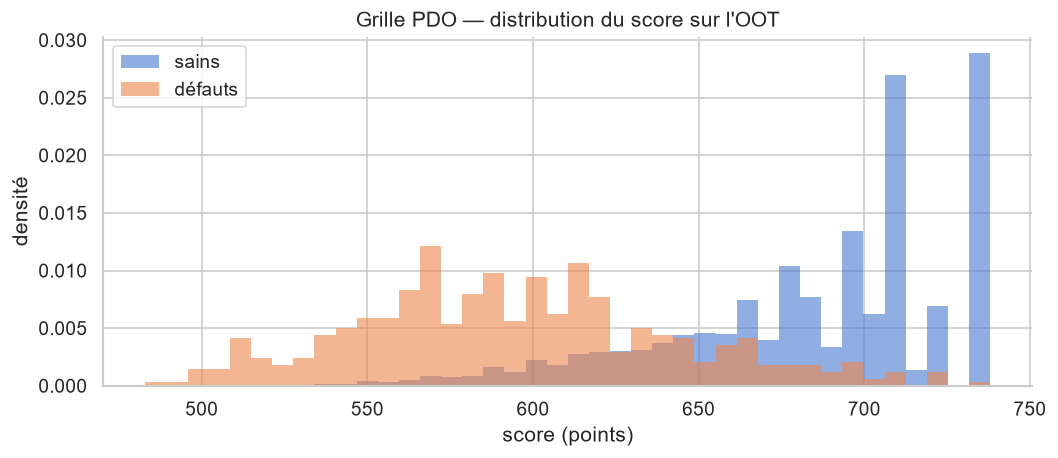

In [11]:
fig = plot_distribution_score(oot_cl["points"], oot_cl[TARGET], titre="Grille PDO — distribution du score sur l'OOT")
plt.show()

## 4. Pouvoir discriminant hors période (5.3, 9.1)

Gini (= 2 AUC − 1) avec son IC à 95 % (Hanley & McNeil) et KS, sur l'apprentissage, le test et l'OOT. On attend une
légère baisse hors période ; un Gini OOT dans l'IC du test indique un modèle robuste.

In [12]:
perf = pl.DataFrame([performance(d[TARGET], -d["points"].to_numpy(), f"grille PDO — {nom}")
                     for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot_cl))])
perf.select("modele", "n", "n_defaut", "auc", "gini", "gini_ic_bas", "gini_ic_haut", "ks")

modele,n,n_defaut,auc,gini,gini_ic_bas,gini_ic_haut,ks
str,i64,i64,f64,f64,f64,f64,f64
"""grille PDO — apprentissage""",47156,228,0.915815,0.83163,0.781772,0.881489,0.695427
"""grille PDO — test""",11791,56,0.898099,0.796199,0.687139,0.905259,0.672444
"""grille PDO — OOT""",94328,530,0.907004,0.814008,0.779886,0.84813,0.671376


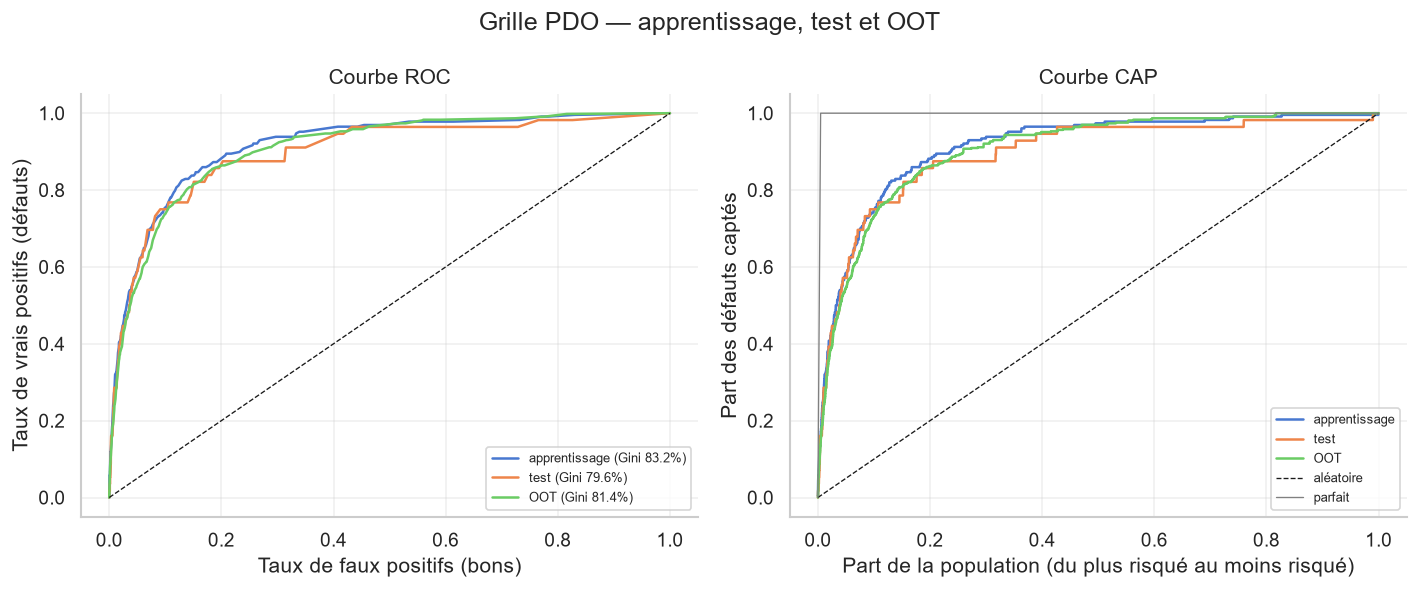

In [13]:
fig = plot_roc_cap({nom: (d[TARGET], -d["points"].to_numpy())
                    for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot_cl))},
                   titre="Grille PDO — apprentissage, test et OOT")
plt.show()

In [14]:
# Gini par cohorte mensuelle : le pouvoir discriminant est-il stable d'un mois à l'autre ?
pl.concat([performance_par_groupe(d, TARGET, "points", "cohorte").with_columns(echantillon=pl.lit(nom))
           for nom, d in (("développement (app. + test)", dev), ("OOT", oot_cl))]) \
  .select("echantillon", "cohorte", "n", "n_defaut", "gini", "gini_ic_bas", "gini_ic_haut", "ks")

echantillon,cohorte,n,n_defaut,gini,gini_ic_bas,gini_ic_haut,ks
str,str,i64,i64,f64,f64,f64,f64
"""développement (app. + test)""","""2021-01""",14668,71,0.789199,0.690985,0.887414,0.660101
"""développement (app. + test)""","""2021-02""",14738,65,0.768794,0.662232,0.875355,0.633862
"""développement (app. + test)""","""2021-03""",14704,67,0.909298,0.839642,0.978953,0.8151
"""développement (app. + test)""","""2021-04""",14837,81,0.829812,0.745768,0.913856,0.710474
"""OOT""","""2024-12""",94328,530,0.814008,0.779886,0.84813,0.671376


In [15]:
table_lift(oot_cl[TARGET], -oot_cl["points"].to_numpy())

decile,n,n_defaut,taux_defaut,lift,part_defauts_captes,lift_cumule
i64,u32,f64,f64,f64,f64,f64
1,9433,387.0,0.041026,7.301732,0.730189,7.301732
2,9433,68.0,0.007209,1.282992,0.858491,4.292362
3,9433,30.0,0.00318,0.566026,0.915094,3.05025
4,9433,17.0,0.001802,0.320748,0.94717,2.367874
5,9432,10.0,0.00106,0.188695,0.966038,1.932075
6,9433,9.0,0.000954,0.169808,0.983019,1.638359
7,9433,0.0,0.0,0.0,0.983019,1.404304
8,9433,4.0,0.000424,0.07547,0.990566,1.238198
9,9433,4.0,0.000424,0.07547,0.998113,1.109004


**Lecture** :

- **Gini OOT = 81,4 %**, IC à 95 % [78,0 % ; 84,8 %], avec un KS de 67,1 %. Il est **supérieur au Gini du test**
  (79,6 %) et à peine inférieur à celui de l'apprentissage (83,2 %). Les 530 défauts OOT donnent un IC deux fois plus
  étroit que le test (56 défauts) : c'est la mesure la plus précise du pouvoir discriminant du modèle.
- Le Gini OOT reste dans la plage des mois de développement (76,9 % à 90,9 %). **Aucune perte de pouvoir
  discriminant** n'apparaît après 3 ans et 8 mois.
- **Lift** : le décile le plus risqué capte **73 % des défauts** (lift de 7,3), et les trois premiers déciles en
  captent 92 %. Le décile 7 n'a aucun défaut et les déciles 8 à 10 n'en ont que 9 au total.

## 5. Modèle concurrent sur l'OOT (5.2)

Le gradient boosting du notebook `5_v2` (51 variables brutes préparées) est réentraîné à l'identique (mêmes données,
mêmes paramètres, même graine) puis appliqué à l'OOT. Les variables qualitatives reçoivent la modalité `missing`
comme en `2` ; la winsorisation de `2` n'a pas d'effet sur un modèle à seuils appris dans les bornes de
l'apprentissage. Le test de DeLong compare les deux AUC sur les mêmes dossiers OOT.

In [16]:
brut = pl.read_parquet(BASE_PREP)
VARS_GB = [v for v in json.loads(CANDIDATES.read_text(encoding="utf-8")) if v in brut.columns]
absentes_gb = [v for v in VARS_GB if v not in oot.columns]
assert not absentes_gb, f"Variables du concurrent absentes de l'OOT : {absentes_gb}"
brut_app  = brut.filter(pl.col("echantillon") == "apprentissage")
brut_test = brut.filter(pl.col("echantillon") == "test")

gb = gradient_boosting(brut_app, VARS_GB, TARGET)
QUALI_GB = [v for v in VARS_GB if not brut.schema[v].is_numeric()]
oot_gb = missing_en_modalite(oot, QUALI_GB)
if HARMONISER:   # même harmonisation de la casse, sur les modalités vues par le boosting en apprentissage
    oot_gb, _ = harmoniser_modalites(oot_gb, {v: list(gb.codes_[v]) for v in QUALI_GB})
p_gb = {"apprentissage": predire_gb(gb, brut_app), "test": predire_gb(gb, brut_test), "OOT": predire_gb(gb, oot_gb)}
y_gb = {"apprentissage": brut_app[TARGET], "test": brut_test[TARGET], "OOT": oot_gb[TARGET]}
print(f"{len(VARS_GB)} variables brutes | {gb.n_iter_} itérations retenues par arrêt précoce")

perf_comp = pl.concat([perf, pl.DataFrame([performance(y_gb[e], p_gb[e], f"gradient boosting — {e}") for e in p_gb])])
perf_comp.select("modele", "n", "n_defaut", "gini", "gini_ic_bas", "gini_ic_haut", "ks")

51 variables brutes | 106 itérations retenues par arrêt précoce


modele,n,n_defaut,gini,gini_ic_bas,gini_ic_haut,ks
str,i64,i64,f64,f64,f64,f64
"""grille PDO — apprentissage""",47156,228,0.83163,0.781772,0.881489,0.695427
"""grille PDO — test""",11791,56,0.796199,0.687139,0.905259,0.672444
"""grille PDO — OOT""",94328,530,0.814008,0.779886,0.84813,0.671376
"""gradient boosting — apprentiss…",47156,228,0.913271,0.876291,0.950251,0.781968
"""gradient boosting — test""",11791,56,0.825969,0.723925,0.928014,0.713385
"""gradient boosting — OOT""",94328,530,0.808725,0.774198,0.843252,0.670664


OOT : Gini grille PDO = 81.4% | Gini gradient boosting = 80.9% | écart = +0.5% | p-value DeLong = 0.427


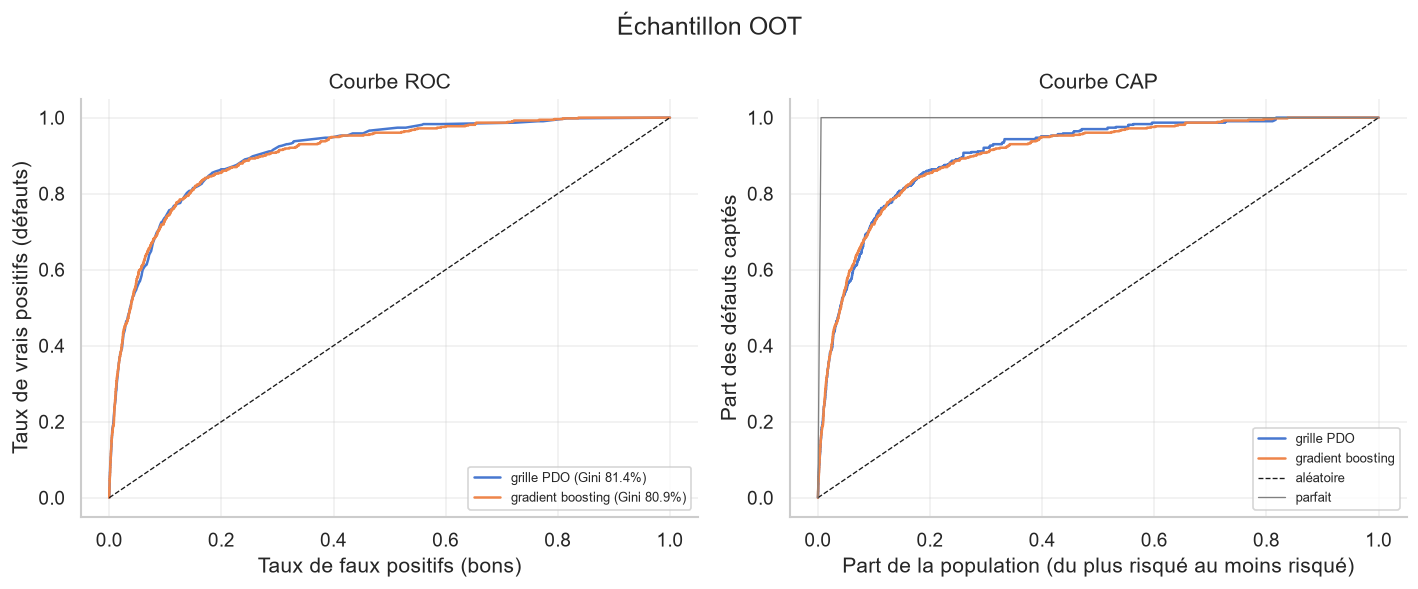

In [17]:
assert (oot_gb[TARGET] == oot_cl[TARGET]).all()   # mêmes dossiers, même ordre
delong = test_delong(oot_cl[TARGET].to_numpy(), -oot_cl["points"].to_numpy(), p_gb["OOT"])
print(f"OOT : Gini grille PDO = {2*delong['auc_a']-1:.1%} | Gini gradient boosting = {2*delong['auc_b']-1:.1%} | "
      f"écart = {delong['ecart_gini']:+.1%} | p-value DeLong = {delong['pvalue']:.3f}")
fig = plot_roc_cap({"grille PDO": (oot_cl[TARGET], -oot_cl["points"].to_numpy()),
                    "gradient boosting": (oot_gb[TARGET], p_gb["OOT"])}, titre="Échantillon OOT")
plt.show()

**Lecture** :

- Le boosting garde l'écart apprentissage / hors échantillon déjà vu en `5_v2` : 91,3 % en apprentissage, 82,6 %
  sur le test, **80,9 % sur l'OOT**. La grille PDO (9 variables) obtient 81,4 % sur l'OOT, avec un écart de
  +0,5 point en sa faveur.
- **DeLong : p = 0,43**. Sur 530 défauts, les deux modèles sont **statistiquement équivalents**. Le surcroît de
  complexité du concurrent (51 variables, 106 arbres) n'apporte rien hors période. Le choix de la régression
  logistique, interprétable et conforme, est confirmé.

## 6. Stabilité de la population (9.3)

**PSI** (Population Stability Index) de la répartition par CHR et **CSI** (Characteristic Stability Index) de chaque
variable en classes, l'apprentissage servant de référence : $\sum_k (p_k^{OOT} - p_k^{app}) \ln(p_k^{OOT}/p_k^{app})$.
Seuils usuels : < 0,10 stable ; 0,10 – 0,25 à surveiller ; > 0,25 glissement significatif. On vérifie aussi que,
dans l'OOT, le taux de défaut croît toujours d'une classe à la suivante (classe 1 = la moins risquée).

In [18]:
detail_stab, stab = stabilite_classes(dev_app, oot_cl, ["CHR", *VARS], TARGET, ("app", "oot"))
_, stab_test = stabilite_classes(dev_app, dev_test, ["CHR", *VARS], TARGET, ("app", "test"))
stab = stab.join(stab_test.select("variable", psi_test="psi"), on="variable").select(
    "variable", "n_classes", "psi_test", "psi", "lecture", "paires_adjacentes", "inversions_cible")
stab

variable,n_classes,psi_test,psi,lecture,paires_adjacentes,inversions_cible
str,i64,f64,f64,str,i64,i64
"""CHR""",4,0.00011,0.002311,"""stable""",3,0
"""MINSOLDE_PAR""",3,0.000127,0.005127,"""stable""",2,0
"""solde_crediteur""",2,0.000374,0.001852,"""stable""",1,0
"""CRTAD_AG_NBJDE_BA""",4,0.000088,0.001268,"""stable""",3,0
"""ENCOURS_PAR""",2,0.000046,0.003551,"""stable""",1,0
"""ARR_GDT""",2,0.000134,0.008626,"""stable""",1,0
"""anciennete_jour_sain_M0""",3,0.000062,0.004963,"""stable""",2,0
"""CAUSE_SAIN_M0""",2,0.000134,0.005863,"""stable""",1,0
"""horsbilan""",2,0.000139,0.004762,"""stable""",1,0


In [19]:
with pl.Config(tbl_rows=-1):
    display(detail_stab.select("variable", "classe", "part_app", "part_oot", "taux_app", "taux_oot", "n_defaut_oot"))

variable,classe,part_app,part_oot,taux_app,taux_oot,n_defaut_oot
str,i64,f64,f64,f64,f64,f64
"""CHR""",1,0.589448,0.611462,0.000288,0.000485,28.0
"""CHR""",2,0.278056,0.258333,0.002441,0.003734,91.0
"""CHR""",3,0.075176,0.073234,0.012976,0.015779,109.0
"""CHR""",4,0.05732,0.056971,0.052534,0.056197,302.0
"""MINSOLDE_PAR""",1,0.699975,0.73201,0.000939,0.001463,101.0
"""MINSOLDE_PAR""",2,0.199826,0.180551,0.00849,0.007574,129.0
"""MINSOLDE_PAR""",3,0.100199,0.08744,0.024762,0.036372,300.0
"""solde_crediteur""",1,0.899949,0.912486,0.00271,0.003392,292.0
"""solde_crediteur""",2,0.100051,0.087514,0.023951,0.028831,238.0


In [20]:
# Sensibilité au traitement des modalités : sans harmonisation de la casse, « EER » est une modalité inconnue et
# reçoit la classe_inconnue du ch. 4 (classe 2, la plus risquée)
oot_sens = scorer_nouvelle_base(oot_non_harmonise, decoupages, g["fusions"], grille, QUALI, "points")
oot_sens = oot_sens.with_columns(CHR=pl.Series(affecter_chr(oot_sens["points"], BORNES)))
sens = []
for nom, d in (("retenu : casse harmonisée", oot_cl), ("sans harmonisation", oot_sens)):
    p = performance(d[TARGET], -d["points"].to_numpy())
    v = table_verification(d, "CHR", TARGET, PD_LRA, ALPHA)
    sens.append({"traitement": nom, "gini": p["gini"], "ks": p["ks"],
                 **{f"part_CHR{k}": x for k, x in zip(v["CHR"], v["n"] / v["n"].sum())},
                 **{f"taux_CHR{k}": x for k, x in zip(v["CHR"], v["taux_observe"])},
                 "attendus_lra": v["attendus"].sum(), "observes": int(v["n_defaut"].sum()),
                 "psi_CHR": stabilite_classes(dev_app, d, ["CHR"], TARGET)[1]["psi"][0]})
pl.DataFrame(sens)

traitement,gini,ks,part_CHR1,part_CHR2,part_CHR3,part_CHR4,taux_CHR1,taux_CHR2,taux_CHR3,taux_CHR4,attendus_lra,observes,psi_CHR
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64
"""retenu : casse harmonisée""",0.814008,0.671376,0.611462,0.258333,0.073234,0.056971,0.000485,0.003734,0.015779,0.056197,447.562989,530,0.002311
"""sans harmonisation""",0.793654,0.6443,0.567488,0.252491,0.090662,0.089358,0.000467,0.003149,0.010056,0.040811,626.660957,530,0.020425


**Lecture** :

- **PSI des CHR = 0,002**, et le **CSI des 9 variables est inférieur à 0,01** : la population OOT est **stable**, très
  en dessous du seuil de 0,10. Aucune paire de classes adjacentes n'est inversée dans l'OOT : chaque variable garde
  son sens de risque.
- Les taux de défaut OOT sont légèrement plus élevés dans presque toutes les classes, ce qui correspond à un niveau de
  risque global plus haut (section 8), pas à une déformation du modèle.
- **Sensibilité à l'harmonisation** : sans correction de la casse, le Gini tomberait à 79,4 %, le PSI des CHR
  monterait à 0,020, le CSI de `CAUSE_SAIN_M0` à 0,41 (glissement significatif) et la part de la CHR 4 passerait de
  5,7 % à 8,9 %. La conclusion sur la discrimination ne change pas, mais le calibrage serait faussé, avec 627 défauts
  attendus contre 448. L'harmonisation est donc nécessaire pour comparer l'OOT au développement.

## 7. Les CHR sur l'OOT (7.2, 7.4, 7.6)

Mêmes bornes de points qu'au ch. 7. Contrôles : ordre strict des taux de défaut, écart relatif $R_k$ entre CHR
adjacentes (règle des 30 %, avec IC), et perte de Gini due à la mise en classe.

In [21]:
tab = {nom: table_chr(d, "CHR", TARGET, SEUIL, ALPHA, points="points")
       for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot_cl))}
pl.concat([t.select(pl.lit(nom).alias("echantillon"), "CHR", "n", "part", "n_defaut", "taux_defaut", "R", "R_ic_bas",
                    "ecart_ok", "ecart_ic_ok") for nom, t in tab.items()]) \
  .with_columns(score=pl.col("CHR").replace_strict(LIBELLES)).sort("CHR", "echantillon")

echantillon,CHR,n,part,n_defaut,taux_defaut,R,R_ic_bas,ecart_ok,ecart_ic_ok,score
str,i64,u32,f64,f64,f64,f64,f64,bool,bool,str
"""OOT""",1,57678,0.611462,28.0,0.000485,null,null,null,null,"""> 676"""
"""apprentissage""",1,27796,0.589448,8.0,0.000288,null,null,null,null,"""> 676"""
"""test""",1,6957,0.590026,3.0,0.000431,null,null,null,null,"""> 676"""
"""OOT""",2,24368,0.258333,91.0,0.003734,6.692609,3.436313,true,true,"""]629 ; 676]"""
"""apprentissage""",2,13112,0.278056,32.0,0.002441,7.479561,0.912434,true,true,"""]629 ; 676]"""
"""test""",2,3237,0.274531,10.0,0.003089,6.164041,-3.07422,true,false,"""]629 ; 676]"""
"""OOT""",3,6908,0.073234,109.0,0.015779,3.225252,2.054752,true,true,"""]600 ; 629]"""
"""apprentissage""",3,3545,0.075176,46.0,0.012976,4.316925,1.926206,true,true,"""]600 ; 629]"""
"""test""",3,906,0.076838,8.0,0.00883,1.858278,-0.790687,true,false,"""]600 ; 629]"""


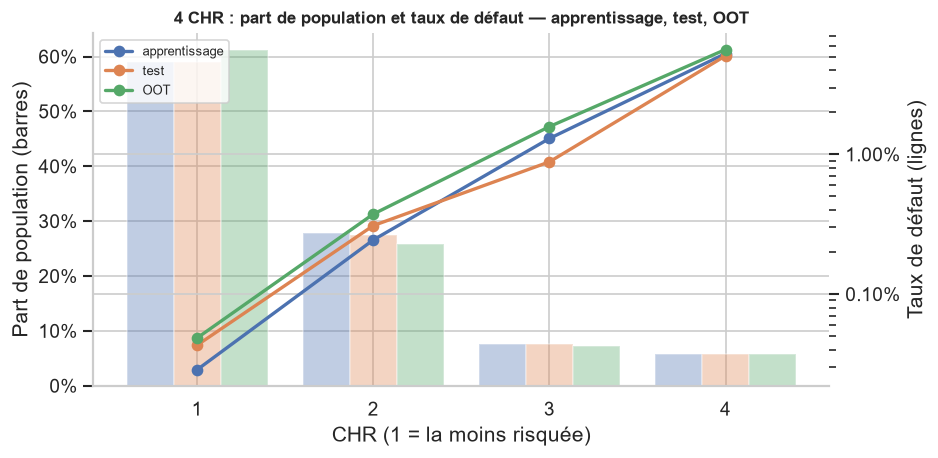

In [22]:
fig = plot_chr(tab, titre=f"{K} CHR : part de population et taux de défaut — apprentissage, test, OOT")
plt.show()

In [23]:
pl.concat([perte_information(d[TARGET], d["points"], d["CHR"], nom) for d, nom in
           ((dev_app, "apprentissage"), (dev_test, "test"), (oot_cl, "OOT"))]) \
  .select("modele", "n_defaut", "gini", "gini_ic_bas", "gini_ic_haut", "ks", "delta_gini")

modele,n_defaut,gini,gini_ic_bas,gini_ic_haut,ks,delta_gini
str,i64,f64,f64,f64,f64,f64
"""score en points — apprentissag…",228,0.83163,0.781772,0.881489,0.695427,0.0
"""CHR — apprentissage""",228,0.804182,0.751024,0.85734,0.695427,0.027449
"""score en points — test""",56,0.796199,0.687139,0.905259,0.672444,0.0
"""CHR — test""",56,0.766361,0.651069,0.881654,0.635433,0.029837
"""score en points — OOT""",530,0.814008,0.779886,0.84813,0.671376,0.0
"""CHR — OOT""",530,0.77095,0.733768,0.808132,0.648912,0.043058


In [24]:
# Ordre des CHR dans chaque cohorte mensuelle de l'OOT (absence de croisement, 8.3.1)
tl_oot = taux_cohortes(oot_cl, "CHR", TARGET, "cohorte")
display(tl_oot.pivot(on="cohorte", index="CHR", values="taux").sort("CHR"))
croisements(tl_oot, "cohorte")

CHR,2024-12
i64,f64
1,0.000485
2,0.003734
3,0.015779
4,0.056197


cohorte,n_inversions,n_defaut,ordre_respecte
str,u32,f64,bool
"""2024-12""",0,530.0,true


**Lecture** :

- Les répartitions sont quasi identiques : 61 % / 26 % / 7 % / 6 % dans l'OOT, contre 59 % / 28 % / 8 % / 6 % en
  apprentissage. Les taux de défaut sont **strictement croissants** : 0,05 % · 0,37 % · 1,58 % · 5,62 %.
- **Hétérogénéité inter-CHR (7.4)** : les trois écarts relatifs $R_k$ dépassent 30 %, **y compris leur borne basse
  d'IC** (3,4 · 2,1 · 1,8, soit +340 % à +180 % au minimum). Sur le test, avec ses 56 défauts, deux de ces IC ne
  concluaient pas. L'OOT confirme que les 4 CHR sont bien distinctes.
- **Perte d'information (7.6)** : ΔGini = 4,3 points (CHR à 77,1 % contre 81,4 % pour le score), un peu plus qu'en
  développement (2,7 à 3,0 points). Le passage du score à 4 classes reste acceptable.

## 8. Calibrage sur l'OOT (8.6, 8.7, 9.2)

Les PD par CHR restent celles du ch. 8 : **PD LRA** (calibrée) et **PD finale** (LRA + MoC A, B, C, plancher).
Sur l'OOT :

- **défauts attendus contre observés** et **test binomial** par CHR : $P(D \geq d \mid PD)$ petite = risque sous-estimé ;
- **Brier**, décomposition de Murphy et **Hosmer-Lemeshow** (ddl = K, échantillon indépendant du calibrage) ;
- **facteur systémique** $Z_t$ de chaque mois OOT (modèle ASRF, ρ du ch. 8) : $Z < 0$ indique une conjoncture plus
  dégradée que la période de développement, ce que la MoC B était censée couvrir.

In [25]:
verif = {nom: table_verification(d, "CHR", TARGET, PD_LRA, ALPHA)
         for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot_cl))}
verif_finale = table_verification(oot_cl, "CHR", TARGET, PD_FINALE, ALPHA)
display(verif["OOT"].join(verif_finale.select("CHR", pd_finale="pd_predite", attendus_pd_finale="attendus",
                                              pvalue_sous_estim_pd_finale="pvalue_sous_estimation"), on="CHR")
        .select("CHR", "n", "n_defaut", "taux_observe", "obs_wilson_bas", "obs_wilson_haut", "pd_predite", "attendus",
                "pd_dans_ic", "pvalue_sous_estimation", "pd_finale", "attendus_pd_finale", "pvalue_sous_estim_pd_finale"))
print(f"OOT : {int(verif['OOT']['n_defaut'].sum())} défauts observés | {verif['OOT']['attendus'].sum():.1f} attendus "
      f"avec la PD LRA | {verif_finale['attendus'].sum():.1f} avec la PD finale")

CHR,n,n_defaut,taux_observe,obs_wilson_bas,obs_wilson_haut,pd_predite,attendus,pd_dans_ic,pvalue_sous_estimation,pd_finale,attendus_pd_finale,pvalue_sous_estim_pd_finale
i64,u32,f64,f64,f64,f64,f64,f64,bool,f64,f64,f64,f64
1,57678,28.0,0.000485,0.000336,0.000702,0.000288,16.5976,false,0.00656,0.000712,41.072176,0.98703
2,24368,91.0,0.003734,0.003043,0.004582,0.002435,59.334325,false,0.000079,0.004454,108.526406,0.961578
3,6908,109.0,0.015779,0.013098,0.018998,0.012979,89.656313,false,0.025229,0.021739,150.171391,0.999842
4,5374,302.0,0.056197,0.05035,0.062677,0.05247,281.974751,true,0.116849,0.076031,408.589783,1.0


OOT : 530 défauts observés | 447.6 attendus avec la PD LRA | 708.4 avec la PD finale


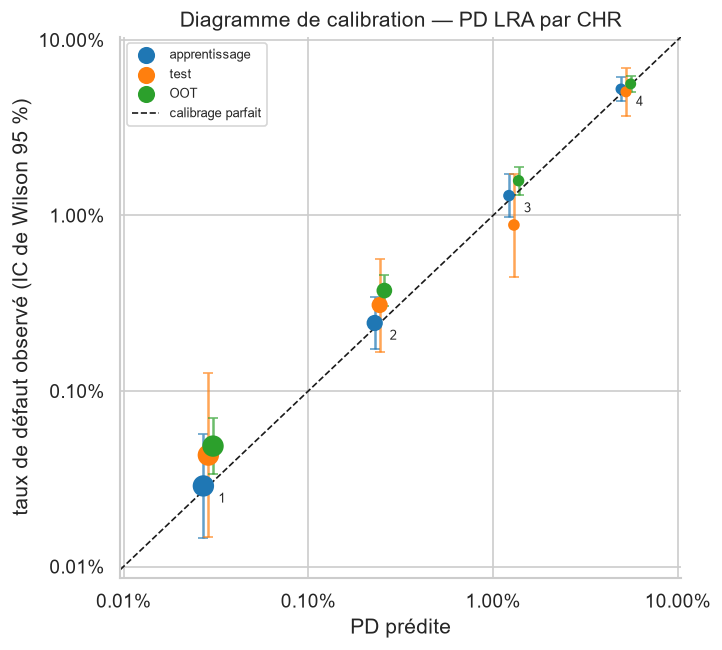

In [26]:
fig = plot_diagramme_calibration(verif, titre="Diagramme de calibration — PD LRA par CHR")
plt.show()

In [27]:
METHODES = {"LRA": PD_LRA, "PD finale (LRA + MoC)": PD_FINALE}
synth = pl.concat([synthese_calibrage(d, "CHR", TARGET, METHODES, nom)
                   for nom, d in (("apprentissage", dev_app), ("test", dev_test), ("OOT", oot_cl))])
synth.select("echantillon", "methode", "brier", "incertitude", "resolution", "calibration", "attendus", "observes",
             "hl", "hl_pvalue", "n_chr_hors_ic")

echantillon,methode,brier,incertitude,resolution,calibration,attendus,observes,hl,hl_pvalue,n_chr_hors_ic
str,str,f64,f64,f64,f64,f64,i64,f64,f64,i64
"""apprentissage""","""LRA""",0.004662,0.004812,0.000149,2.4426e-10,227.761548,228,0.000393,1.0,0
"""apprentissage""","""PD finale (LRA + MoC)""",0.004701,0.004812,0.000149,0.000039,360.764867,228,53.059347,8.2815e-11,4
"""test""","""LRA""",0.004592,0.004727,0.000137,0.000002,57.899355,56,2.331521,0.675036,0
"""test""","""PD finale (LRA + MoC)""",0.004641,0.004727,0.000137,0.000051,91.603125,56,15.565253,0.003662,2
"""OOT""","""LRA""",0.005419,0.005587,0.00017,0.000002,447.562989,530,30.505512,0.000004,3
"""OOT""","""PD finale (LRA + MoC)""",0.005442,0.005587,0.00017,0.000025,708.359756,530,48.639493,6.9427e-10,3


In [28]:
# Défauts observés / attendus et facteur systémique Z de chaque mois (dév. et OOT, PD LRA comme PD TTC)
tl_dev = taux_cohortes(dev, "CHR", TARGET, "cohorte")
z = pl.concat([estimer_z(t, PD_LRA, {k: RHO for k in PD_LRA}, "cohorte").with_columns(echantillon=pl.lit(nom))
               for nom, t in (("développement", tl_dev), ("OOT", tl_oot))])
z.with_columns(ratio_obs_att=pl.col("n_defaut") / pl.col("attendus_ttc")).select(
    "echantillon", "cohorte", "n_defaut", "attendus_ttc", "ratio_obs_att", "z")

echantillon,cohorte,n_defaut,attendus_ttc,ratio_obs_att,z
str,str,i64,f64,f64,f64
"""développement""","""2021-01""",71,70.49221,1.007203,-0.299548
"""développement""","""2021-02""",65,72.482558,0.896767,-0.064155
"""développement""","""2021-03""",67,71.119937,0.942071,-0.006674
"""développement""","""2021-04""",81,71.566198,1.131819,-0.460951
"""OOT""","""2024-12""",530,447.562989,1.184191,-0.620504


**Lecture** :

- **La PD LRA sous-estime le risque de l'OOT** : 530 défauts observés pour 447,6 attendus, soit un ratio de 1,18.
  Les CHR 1 à 3 ont un taux observé au-dessus de l'IC de leur PD (test binomial p = 0,007 · 0,0001 · 0,025). La CHR 4
  est correcte (p = 0,12). Hosmer-Lemeshow rejette le calibrage LRA (p < 0,001).
- La décomposition de Murphy montre que le problème porte sur le **niveau** : la résolution OOT (0,00017) est même
  meilleure qu'en développement, l'ordre est intact, mais toutes les classes ont glissé vers le haut.
- **Lecture ASRF** : le facteur systémique de décembre 2024 vaut **Z = −0,62**. La conjoncture est plus dégradée que
  tous les mois de développement (de −0,46 à −0,01), ce qui correspond à une PD point-in-time au-dessus de la PD TTC.
  C'est exactement le risque que la **MoC B** devait couvrir. Le choc retenu (ΔZ = 0,5) est un peu plus faible que
  l'écart constaté, mais du même ordre.
- **La PD finale (LRA + MoC) couvre les défauts de chaque CHR** : 708 attendus pour 530 observés, et un test de
  sous-estimation non significatif dans les 4 CHR (p ≥ 0,96). La marge de prudence joue son rôle. Hosmer-Lemeshow la
  rejette aussi (p < 0,001), mais cette fois par excès de prudence, ce qui est l'effet recherché d'une MoC.

### Échelle maître (7.5)

Chaque CHR est rattachée à un **grade de l'échelle maître** commune aux segments : 11 grades définis par des bornes de
PD qui doublent d'un grade au suivant (0,05 % · 0,1 % · … · 25,6 %), convention ]pd_min ; pd_max]. On place la PD LRA,
la PD finale et le taux de défaut observé sur l'OOT : si le taux observé tombe dans le grade de la PD finale, le
grade attribué reste valable hors période de développement.

In [29]:
em = echelle_maitre()
v = verif["OOT"].sort("CHR")
pd_lra = np.array([PD_LRA[k] for k in v["CHR"]])
pd_fin = np.array([PD_FINALE[k] for k in v["CHR"]])
grades = v.select("CHR", "n", "n_defaut", "taux_observe").with_columns(
    pd_lra=pl.Series(pd_lra), grade_pd_lra=pl.Series(affecter_grade(pd_lra)),
    pd_finale=pl.Series(pd_fin), grade_pd_finale=pl.Series(affecter_grade(pd_fin)),
    grade_taux_oot=pl.Series(affecter_grade(v["taux_observe"])))
# Grades de l'échelle et CHR qui y sont rattachées (par la PD finale)
em_chr = em.join(grades.group_by("grade_pd_finale").agg(CHR=pl.col("CHR").cast(pl.String).str.join(", ")),
                 left_on="grade", right_on="grade_pd_finale", how="left")
display(em_chr)
grades

grade,pd_min,pd_max,CHR
i64,f64,f64,str
1,0.0,0.0005,null
2,0.0005,0.001,"""1"""
3,0.001,0.002,null
4,0.002,0.004,null
5,0.004,0.008,"""2"""
6,0.008,0.016,null
7,0.016,0.032,"""3"""
8,0.032,0.064,null
9,0.064,0.128,"""4"""


CHR,n,n_defaut,taux_observe,pd_lra,grade_pd_lra,pd_finale,grade_pd_finale,grade_taux_oot
i64,u32,f64,f64,f64,i64,f64,i64,i64
1,57678,28.0,0.000485,0.000288,1,0.000712,2,1
2,24368,91.0,0.003734,0.002435,4,0.004454,5,4
3,6908,109.0,0.015779,0.012979,6,0.021739,7,6
4,5374,302.0,0.056197,0.05247,8,0.076031,9,8


**Lecture** :

- **Une CHR par grade, un grade vide entre deux CHR** : grades 2 · 5 · 7 · 9 avec la PD finale. Chaque CHR a une
  PD 3 à 9 fois plus élevée que la précédente, ce qui la place deux grades plus haut. L'échelle conserve l'ordre et la
  séparation des CHR, sans en fusionner deux.
- **La MoC décale chaque CHR d'exactement un grade** (1 · 4 · 6 · 8 avec la PD LRA).
- **Le taux observé sur l'OOT tombe dans le grade de la PD LRA pour les 4 CHR**, donc un grade sous celui de la
  PD finale : la PD finale est conservatrice d'un grade sur l'OOT, malgré la conjoncture dégradée (Z = −0,62).
- Deux taux observés sont **proches d'une borne** : CHR 1 à 0,049 % (borne 0,05 %) et CHR 3 à 1,58 % (borne 1,6 %).
  Une légère dégradation les ferait passer dans le grade de leur PD finale, qui reste alors couvrante.
- 7 grades sur 11 sont vides, dont les 3 intercalaires : ils laissent la place aux CHR d'un autre segment sur la même
  échelle.

### Conclusions

| Contrôle | Développement (test) | OOT déc. 2024 | Verdict |
|----------|----------------------|---------------|---------|
| Gini du score (IC 95 %) | 79,6 % [68,7 ; 90,5] | **81,4 % [78,0 ; 84,8]** | robuste |
| Gini du concurrent (boosting) | 82,6 % | 80,9 % (DeLong p = 0,43) | logistique confirmée |
| PSI des CHR / CSI max. des variables | 0,000 / 0,000 | 0,002 / < 0,01 | population stable |
| Ordre des 4 CHR, IC de $R_k$ ≥ 30 % | ordre OK, 1 IC sur 3 concluant | ordre OK, **3 IC sur 3** | CHR distinctes |
| Défauts observés / attendus, PD LRA | 56 / 57,9 | 530 / 447,6 (ratio 1,18) | sous-estimation PIT |
| Défauts observés / attendus, PD finale | 56 / 91,6 | 530 / 708,4 | **PD prudente** |

1. **Risk differentiation** : le modèle garde tout son pouvoir discriminant 3 ans et 8 mois après sa construction
   (Gini OOT de 81,4 %), avec des CHR ordonnées et nettement séparées. Le gradient boosting ne fait pas mieux.
2. **Risk quantification** : la PD LRA, estimée sur 4 mois de 2021, est trop basse pour décembre 2024, qui se trouve
   dans une conjoncture plus dégradée (Z = −0,62). La **PD réglementaire avec MoC reste conservatrice dans chaque
   CHR**, ce qui valide la logique de la MoC B. Un recalibrage du niveau (LRA élargie à des cohortes 2022–2024) serait
   la première action de suivi. Il ne toucherait ni la grille ni les bornes.
3. **Qualité des données** : la livraison OOT code la cause de retour en sain `EER` en majuscules pour 14,6 % des
   dossiers. Le recodage de la casse est indispensable, et documenté ici. La différence de taux de défaut entre `EER`
   et `eer` doit être éclaircie avec les fournisseurs de la donnée.
4. **Limites** : un seul mois d'OOT, donc pas de mesure de stabilité mois par mois après 2021, et des volumes mensuels
   très différents des bases de développement (échantillonnage à vérifier).

In [30]:
def sans_nan(t):   # Excel n'accepte ni NaN ni infini
    return t.with_columns(pl.when(pl.col(pl.Float64).is_finite()).then(pl.col(pl.Float64)).otherwise(None))

SORTIE_XLS.parent.mkdir(parents=True, exist_ok=True)
exporter_excel({k: sans_nan(v) for k, v in {
    "perimetre": suivi_perimetre, "periodes": periodes, "controle_variables": controle,
    "performance": perf_comp, "stabilite_psi_csi": stab, "stabilite_detail": detail_stab,
    "chr_oot": tab["OOT"], "calibrage_oot": verif["OOT"], "calibrage_pd_finale": verif_finale,
    "synthese_calibrage": synth, "facteur_z": z,
    "echelle_maitre": em_chr, "grades_chr": grades}.items()}, SORTIE_XLS)
print(f"Tables : {SORTIE_XLS}")

Tables : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\resultats\resultats_oot_joint_v2.xlsx
